# Letter Recognition (A–Z)

The original OCR benchmark: 20,000 capital letters rendered in 20 different fonts, each reduced to 16 statistical features (edge counts, moments, bounding-box ratios). Recognise the letter — all **26 classes** — from numbers alone.


In [1]:
import io, urllib.request, zipfile, gzip
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r:
        return r.read()
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

raw = download('https://archive.ics.uci.edu/static/public/59/letter+recognition.zip')
zf = zipfile.ZipFile(io.BytesIO(raw))
name = [n for n in zf.namelist() if n.endswith('.data')][0]
df = pd.read_csv(io.BytesIO(zf.read(name)), header=None)
print(df.shape)
df.head(3)

(20000, 17)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
0,T,2,8,3,5,1,8,13,0,6,6,10,8,0,8,0,8
1,I,5,12,3,7,2,10,5,5,4,13,3,9,2,8,4,10
2,D,4,11,6,8,6,10,6,2,6,10,3,7,3,7,3,9


In [2]:
y = df.iloc[:, 0]; X = df.iloc[:, 1:]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
print(f'Random Forest accuracy: {accuracy_score(yte, rf.predict(Xte)):.4f}')
print(f'Logistic Regression accuracy: {accuracy_score(yte, lr.predict(Xte)):.4f}')
print(classification_report(yte, rf.predict(Xte)))

Random Forest accuracy: 0.9700
Logistic Regression accuracy: 0.7712


              precision    recall  f1-score   support

           A       0.99      1.00      0.99       197
           B       0.92      0.97      0.95       192
           C       0.98      0.96      0.97       184
           D       0.93      0.99      0.96       201
           E       0.95      0.97      0.96       192
           F       0.97      0.96      0.97       194
           G       0.96      0.93      0.95       193
           H       0.93      0.90      0.91       183
           I       0.97      0.94      0.96       189
           J       0.95      0.97      0.96       187
           K       0.95      0.95      0.95       185
           L       0.99      0.98      0.99       190
           M       0.98      0.99      0.98       198
           N       0.98      0.95      0.97       196
           O       0.97      0.97      0.97       188
           P       0.99      0.98      0.98       201
           Q       0.96      0.98      0.97       196
           R       0.94    

12    0.116106
14    0.101241
8     0.092717
7     0.085215
11    0.084591
10    0.081590
13    0.073616
9     0.073482
6     0.067932
15    0.055163
5     0.051204
4     0.026530
1     0.025364
2     0.022424
0     0.021709
3     0.021116
dtype: float64


<Axes: title={'center': 'Edge/shape statistics importance'}>

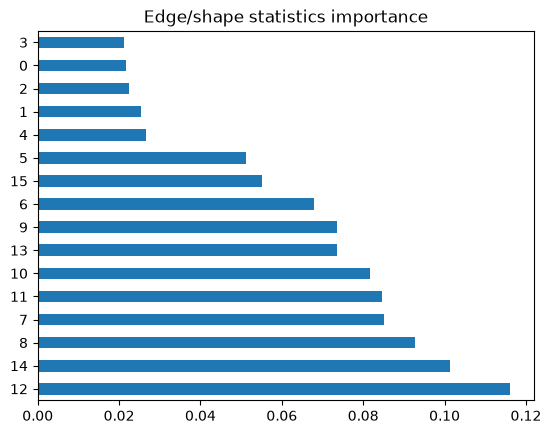

In [3]:
imp = pd.Series(rf.feature_importances_).sort_values(ascending=False)
print(imp)
imp.plot(kind='barh', title='Edge/shape statistics importance')